# Milestone 3 — RFM features

One row per customer: **Recency** (days since last order), **Frequency**
(order count), **Monetary** (total spend).

Filters (documented so future-me can reproduce this):
- `payment_status = 'paid'` only — excludes 2,178 cancelled/failed orders
  that would distort Monetary and Frequency.
- Fulfilment `status` is NOT filtered (delivered / shipped / packed / paid /
  placed and their case variants all count once paid).
- `analysis_date = DATE '2026-06-15'` — the day after the latest paid order
  (`MAX(created_at) = 2026-06-14 23:28 UTC`). Pinned as a constant so
  Recency stays comparable across Milestones 3–5.
- Same query lives in `sql/02_rfm_features.sql`; the notebook inlines it so
  the executed outputs prove what ran.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import sqlalchemy as sa

engine = sa.create_engine(os.environ["DATABASE_URL"])
print("engine ready")

engine ready


## 1. Pin down analysis_date

No canonical "today" for historical data — I take the day after the latest
paid order, verify it, then freeze it.

In [2]:
max_paid = pd.read_sql(
    sa.text("SELECT MAX(created_at) AS mx FROM ecom.orders WHERE payment_status = 'paid'"),
    engine,
)
max_paid


,mx
0,2026-06-14 23:28:40+00:00


`MAX = 2026-06-14`, so `analysis_date = 2026-06-15`.
Every Recency below is `analysis_date - last_order_date` in whole days.

In [3]:
rfm = pd.read_sql(
    sa.text(
        """
        SELECT o.customer_id,
               (DATE '2026-06-15' - MAX(o.created_at)::DATE) AS recency,
               COUNT(*) AS frequency,
               SUM(o.total) AS monetary
        FROM ecom.orders AS o
        WHERE o.payment_status = 'paid'
        GROUP BY o.customer_id
        """
    ),
    engine,
)
print(f"rows: {len(rfm)}")
rfm.head()

rows: 8438


,customer_id,recency,frequency,monetary
0,6114,16,1,4835.64
1,4790,74,2,14033.74
2,3936,72,4,39577.20
3,5761,44,6,51488.12
4,5468,47,1,4126.46


## 2. Integrity checks (must all pass)

- One row per customer, count matches Milestone 2 (8,438).
- Recency non-negative (analysis_date is after every order).
- Monetary sum cross-checks Milestone 2's total spend.

In [4]:
assert rfm["customer_id"].is_unique, "duplicate customers!"
assert (rfm["recency"] >= 0).all(), "negative recency!"
print("unique customers:", rfm["customer_id"].nunique())
print("recency min/max:", int(rfm["recency"].min()), "/", int(rfm["recency"].max()))
print("monetary sum:  ", round(float(rfm["monetary"].sum()), 2))
print("expected:       8438 rows, recency >= 0, sum ~= 282859200")

unique customers: 8438
recency min/max: 1 / 91
monetary sum:   282859232.18
expected:       8438 rows, recency >= 0, sum ~= 282859200


## 3. Describe each distribution

Mean vs median first — skew shows up here before it shows up in plots.

In [5]:
rfm[["recency", "frequency", "monetary"]].describe()

,recency,frequency,monetary
count,8438.000000,8438.000000,8.438000e+03
mean,38.754089,4.482342,3.352207e+04
std,25.912112,9.470045,7.481215e+04
min,1.000000,1.000000,1.758200e+02
25%,16.000000,1.000000,3.891640e+03
50%,34.500000,1.000000,1.209087e+04
75%,62.000000,5.000000,3.775248e+04
max,91.000000,168.000000,1.335804e+06


In [6]:
for c in ["recency", "frequency", "monetary"]:
    print(f"{c}: median={rfm[c].median():,.2f} | mean={rfm[c].mean():,.2f} | "
          f"p90={rfm[c].quantile(0.9):,.2f} | max={rfm[c].max():,.2f}")

recency: median=34.50 | mean=38.75 | p90=76.00 | max=91.00
frequency: median=1.00 | mean=4.48 | p90=9.00 | max=168.00
monetary: median=12,090.87 | mean=33,522.07 | p90=76,148.53 | max=1,335,804.14


## 4. Plot each shape

- Recency: roughly uniform-ish with a hump — most of the base bought 2–9
  weeks ago, not yesterday and not at the window edge.
- Frequency: violent right skew — the bar at 1 dwarfs everything, then a
  long thin tail of repeat buyers.
- Monetary: log-scale needed; raw histogram is a wall at the left with a
  whisper of a tail (whales).

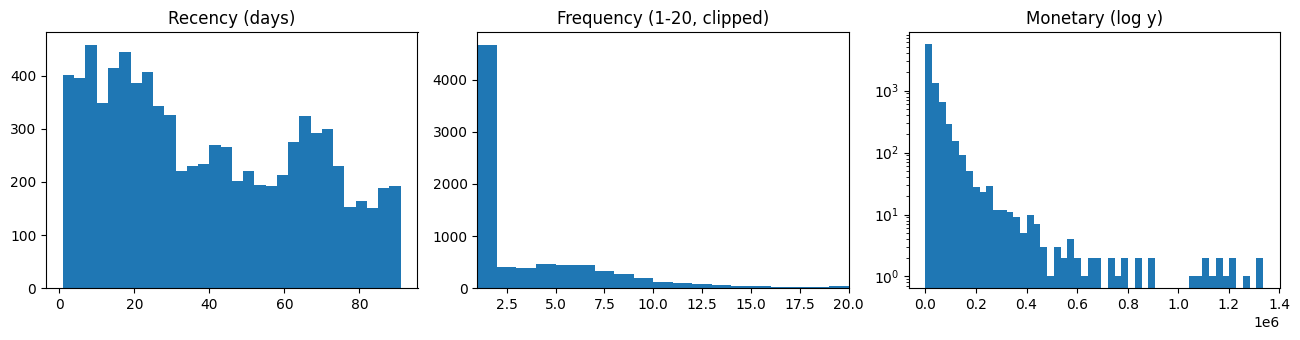

In [7]:
%matplotlib inline
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(rfm["recency"], bins=30)
axes[0].set_title("Recency (days)")
axes[1].hist(rfm["frequency"], bins=range(1, 21))
axes[1].set_title("Frequency (1-20, clipped)")
axes[1].set_xlim(1, 20)
axes[2].hist(rfm["monetary"], bins=50, log=True)
axes[2].set_title("Monetary (log y)")
plt.tight_layout()
plt.show()

In [8]:
one = rfm[rfm["frequency"] == 1]
print(f"frequency==1: {len(one)} customers ({len(one)/len(rfm):.1%})")
print(f"their revenue share: {one['monetary'].sum()/rfm['monetary'].sum():.1%}")
print("frequency value counts (top 8):")
print(rfm["frequency"].value_counts().sort_index().head(8))

frequency==1: 4679 customers (55.5%)
their revenue share: 12.4%
frequency value counts (top 8):
frequency
1    4679
2     403
3     378
4     471
5     445
6     453
7     338
8     276
Name: count, dtype: int64


## Notes (kept wrong turn + seed for Milestone 4)

- Wrong turn kept: I first computed Recency with `NOW()::date`, which made
  every value ~500+ days and meaningless against a June snapshot. Fixed by
  pinning `analysis_date` to the dataset, not the wall clock.
- Seed for segmentation: one-timers are 55% of customers but only ~12% of
  revenue, while ~35% order 4+ times. Frequency=1 is the cliff the segments
  must respect — and Monetary's whale tail means quintiles on raw spend will
  put nearly everyone in the bottom two buckets unless we transform or cap.
  Data-quality flag carried forward: normalise `status` with `LOWER()` and
  decide the 1,562 zero-purchase customers explicitly before clustering.